[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/timeseries/07-metrics-intervals.ipynb)

# Forecast Metrics and Prediction Intervals

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Choose among MAE, RMSE, MAPE, sMAPE, MASE and bias, and say what each hides.</li>
<li>Show how percentage errors fail when demand is near zero.</li>
<li>Build prediction intervals from past forecast errors and test their coverage by group.</li>
<li>Choose the quantile to report when over- and under-forecasting cost different amounts.</li>
</ul>
</div>

**Prerequisites:** Pages 1 to 6 of this track. **Dataset:** NYC Taxi (Jan to Mar 2023). **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import forecasting as fc, style
from mlp_data.timeseries import taxi_hourly

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

The dispatch team has two questions we have not yet answered well. First, *which number tells us a forecaster is good?* We have used MAE, RMSE, sMAPE and MASE somewhat casually, and the choice of metric can crown a different winner or even a useless forecast. Second, a single "expected pickups" number is not what a dispatcher needs to decide how many cabs to field: they need **how bad could it be**, a range.

This page covers both: how forecast metrics behave (and misbehave), and how to attach honest prediction intervals to any forecaster.

In [2]:
from sklearn.ensemble import HistGradientBoostingRegressor
from mlp_data.timeseries import taxi_hourly_by_zone

y = taxi_hourly(["2023-01", "2023-02", "2023-03"]).asfreq("h").interpolate()
H = 24
# Forecast origins from 29 January so that later origins have earlier forecast errors to learn from (used in section 3)
all_origins = fc.rolling_origins(y.index, first_origin="2023-01-29")
four_week = fc.backtest(y, lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=4), origins=all_origins, horizon=H)
last_week = fc.backtest(y, lambda hist, idx: fc.seasonal_naive(hist, idx, 168), origins=all_origins, horizon=H)
scored = lambda bt: bt[bt["origin"] >= "2023-02-12"]            # the 48 origins used on the backtesting page
scale_history = y[:"2023-02-11"]
print(len(all_origins), "origins in total;", scored(four_week)["origin"].nunique(), "scored in section 1")

62 origins in total; 48 scored in section 1


## 1. A scorecard for point forecasts

Every metric is a summary of the errors $e_t = y_t - \hat y_t$. They answer different questions:

| Metric | Formula | Question it answers | Watch out for |
|---|---|---|---|
| **MAE** | mean of $\lvert e_t\rvert$ | typical miss, in the units of the data | ignores the sign; treats all days alike |
| **RMSE** | $\sqrt{\text{mean of } e_t^2}$ | the same, but large misses count more | dominated by a few bad days |
| **MAPE** | mean of $\lvert e_t\rvert / y_t$ | miss as a share of demand | undefined at $y_t = 0$; explodes for small $y_t$ |
| **sMAPE** | mean of $2\lvert e_t\rvert / (\lvert y_t\rvert + \lvert\hat y_t\rvert)$ | a bounded percentage error | rewards forecasting low; odd near zero |
| **MASE** | MAE divided by the in-sample MAE of the seasonal-naive forecast | error relative to a baseline, comparable across series | needs a sensible seasonal period |
| **Bias** | mean of $(\hat y_t - y_t)$ | does the forecaster lean high or low? | cancels positive and negative misses |

All on the same forecasts (the four-week average and the weekly copy, over 48 origins):

In [3]:
def full_scorecard(bt):
    s = fc.score(bt, scale_history)
    return {"MAE": s["MAE"], "RMSE": s["RMSE"], "MAPE": fc.mape(bt["actual"], bt["forecast"]), "sMAPE": s["sMAPE"],
            "MASE": s["MASE"], "bias": (bt["forecast"] - bt["actual"]).mean()}

card = pd.DataFrame({"4-week average": full_scorecard(scored(four_week)), "same hour last week": full_scorecard(scored(last_week))}).T
card.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE": "{:.1%}", "sMAPE": "{:.1%}", "MASE": "{:.2f}", "bias": "{:+,.0f}"})

,MAE,RMSE,MAPE,sMAPE,MASE,bias
4-week average,281,406,7.6%,7.7%,0.77,-78
same hour last week,338,501,9.6%,9.4%,0.92,-20


Three things to read off this table.

**Bias.** The four-week average has a bias of about −78 pickups an hour: it ran *low*, on average, by roughly 1.7% of the average hour's demand (about 4,470 pickups). Demand was rising through the period and a four-week average lags it. MAE cannot show this, because it ignores the sign. When a forecaster leans one way, ask whether the decision cares: under-forecasting demand means too few cabs.

**RMSE versus MAE.** RMSE is about 1.4 times MAE here. Equal values would mean all errors are about the same size; a gap says a few days are much worse. Test how much one day matters by dropping the worst one (Presidents' Day):

In [4]:
ev = scored(four_week)
holiday = ev["origin"] == "2023-02-20"
for name, subset in [("all 48 days", ev), ("without 20 February", ev[~holiday])]:
    print(f"{name:22s} MAE {fc.mae(subset.actual, subset.forecast):6.1f}   RMSE {fc.rmse(subset.actual, subset.forecast):6.1f}")
mae_change = 1 - fc.mae(ev[~holiday].actual, ev[~holiday].forecast) / fc.mae(ev.actual, ev.forecast)
rmse_change = 1 - fc.rmse(ev[~holiday].actual, ev[~holiday].forecast) / fc.rmse(ev.actual, ev.forecast)
print(f"removing one of 48 days lowers MAE by {mae_change:.1%} and RMSE by {rmse_change:.1%}")
assert rmse_change > 1.3 * mae_change

all 48 days            MAE  281.2   RMSE  406.2
without 20 February    MAE  274.6   RMSE  392.0
removing one of 48 days lowers MAE by 2.4% and RMSE by 3.5%


One day in 48 moves RMSE about 50% more than it moves MAE (3.5% against 2.4%). **Choose RMSE if big misses are disproportionately costly** (a day with far too few cabs is much worse than two slightly-off days); choose MAE if cost is roughly proportional to the miss, and it is less jumpy.

**Percentage errors.** MAPE is about 7.6% overall, which sounds reassuring. By hour of day:

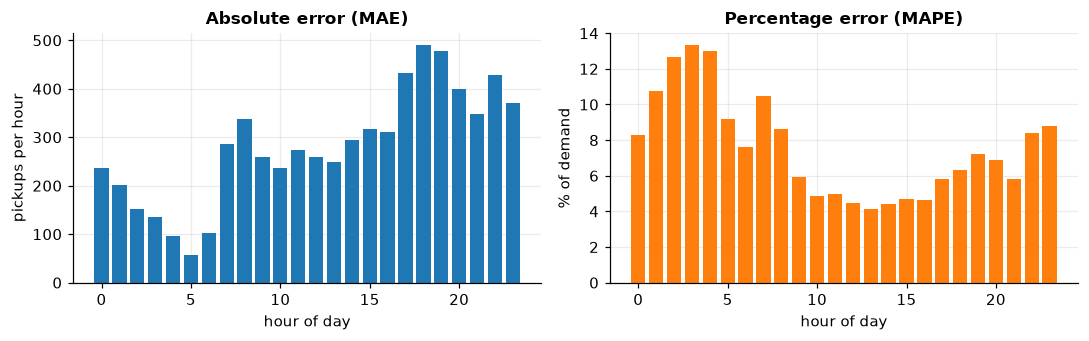

worst hours by MAE:  {18: 490.0, 19: 477.0, 17: 432.0}
worst hours by MAPE: {3: 13.3, 4: 13.0, 2: 12.6}


In [5]:
hour = ev["time"].dt.hour
by_hour = ev.assign(ape=(ev["actual"] - ev["forecast"]).abs() / ev["actual"], abs_error=(ev["actual"] - ev["forecast"]).abs()).groupby(hour).agg(
    MAPE=("ape", "mean"), MAE=("abs_error", "mean"), demand=("actual", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(by_hour.index, by_hour["MAE"], color="tab:blue"); axes[0].set(title="Absolute error (MAE)", xlabel="hour of day", ylabel="pickups per hour")
axes[1].bar(by_hour.index, by_hour["MAPE"] * 100, color="tab:orange"); axes[1].set(title="Percentage error (MAPE)", xlabel="hour of day", ylabel="% of demand")
plt.tight_layout(); plt.show()
print("worst hours by MAE: ", by_hour["MAE"].nlargest(3).round(0).to_dict())
print("worst hours by MAPE:", (by_hour["MAPE"].nlargest(3) * 100).round(1).to_dict())

The two rankings are almost opposite. In absolute terms the evening rush is the problem (about 430 to 490 pickups at 5 to 7pm); in percentage terms the small hours are (13% at 2 to 4am, when demand is low). The metric you choose decides *which hours you work on*. With demand in the thousands a percentage error is merely misleading; with demand near zero it breaks.

## 2. When demand is near zero: count data

A whole city is smooth. A single pickup zone is not. We take one quiet zone (the one whose average is closest to one pickup an hour, excluding the TLC's two "unknown" codes) and forecast *its* hourly counts.

In [6]:
zones = taxi_hourly_by_zone(["2023-01", "2023-02", "2023-03"]).drop(columns=[264, 265]).asfreq("h").dropna()
zone_id = (zones.mean() - 1).abs().idxmin()
zone = zones[zone_id].astype(float)
print(f"zone {zone_id}: mean {zone.mean():.2f} pickups per hour, {(zone == 0).mean():.0%} of hours have none, busiest hour has {int(zone.max())}")
print(zone.value_counts().sort_index().head(7).to_dict())

zone 66: mean 0.92 pickups per hour, 51% of hours have none, busiest hour has 10
{0.0: 1101, 1.0: 535, 2.0: 285, 3.0: 149, 4.0: 53, 5.0: 11, 6.0: 15}


In [7]:
zone_origins = fc.rolling_origins(zone.index, first_origin="2023-02-12")
zone_train = zone[:"2023-02-11"]
zone_forecasters = {
    "4-week average": lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=4),
    "same hour last week": lambda hist, idx: fc.seasonal_naive(hist, idx, 168),
    "flat at the training mean": lambda hist, idx: pd.Series(hist.mean(), index=idx),
    "flat at zero ('never any demand')": lambda hist, idx: pd.Series(0.0, index=idx),
}
rows = {}
for name, f in zone_forecasters.items():
    bt = fc.backtest(zone, f, origins=zone_origins, horizon=H)
    rows[name] = {"MAE": fc.mae(bt.actual, bt.forecast), "RMSE": fc.rmse(bt.actual, bt.forecast),
                  "MAPE": fc.mape(bt.actual, bt.forecast), "sMAPE": fc.smape(bt.actual, bt.forecast),
                  "MASE": fc.mase(bt.actual, bt.forecast, zone_train, 168)}
zone_card = pd.DataFrame(rows).T
zone_card.style.format("{:.3f}")

,MAE,RMSE,MAPE,sMAPE,MASE
4-week average,0.350,0.636,nan,0.745,0.429
same hour last week,0.955,1.532,nan,0.990,1.170
flat at the training mean,0.806,0.905,inf,1.629,0.987
flat at zero ('never any demand'),0.388,0.880,nan,0.493,0.475


This table is the argument for choosing metrics with care.

- **MAPE is undefined** (`nan` or `inf`) for every forecaster: about half the actual values are zero, and a percentage of zero does not exist. A pipeline that reports MAPE would silently fail here, or, worse, drop the zero hours and report a number for a different, easier problem.
- **sMAPE crowns the nonsense forecast.** "Flat at zero", which says *no pickups, ever*, gets a much *better* sMAPE than the four-week average, because every zero hour scores as a perfect match and every non-zero hour is capped at the worst value of 2, which it would not exceed anyway.
- **MAE, RMSE and MASE agree**: the four-week average is best, and "never any demand" is not. MASE (0.43 for the average) reads as *"57% better than last week's copy did in training"*, comparable with any other series.

The lesson: **never evaluate a forecast with a single metric you have not stress-tested on the shape of your data**. For counts with zeros use MAE, RMSE or MASE (or a probabilistic metric such as the Poisson deviance).

## 3. Prediction intervals

A point forecast says "about 5,000 pickups at 6pm". The dispatcher wants "between 4,300 and 5,800, nine times in ten". An **80% prediction interval** should contain the actual value about 80% of the time, and we can check that: a property called *coverage*. Three ways to build one, each usable with any point forecaster:

1. **Gaussian**: forecast ± 1.28 standard deviations of past errors.
2. **Empirical quantiles of past errors**: forecast plus the 10th and 90th percentiles of recent forecast errors (no bell-curve assumption).
3. **Errors by hour, as a share of the forecast**: the same, but computed separately for each hour of the day and expressed *relative* to the forecast, so that quiet hours get narrow intervals and busy ones wide ones.

The key rule is the same as always: the residuals that build the interval at an origin must be ones *already known at that origin*. We reuse the four-week-average backtest from 29 January and, for each origin from 19 February, build intervals from the errors of earlier forecasts whose targets have already happened.

In [8]:
four_week = four_week.assign(hour=four_week["time"].dt.hour)
z80 = 1.2816                                              # standard-normal 90th percentile
rows = []
for origin in [o for o in all_origins if o >= pd.Timestamp("2023-02-19")]:
    known = four_week[four_week["time"] < origin]          # forecast errors that have already been observed
    now = four_week[four_week["origin"] == origin]
    errors = known["actual"] - known["forecast"]
    lo_q, hi_q = errors.quantile([0.1, 0.9])
    relative = (known["actual"] / known["forecast"] - 1).groupby(known["hour"]).quantile([0.1, 0.9]).unstack()
    for _, r in now.iterrows():
        rel_lo, rel_hi = relative.loc[r["hour"]]
        rows.append({"origin": origin, "time": r["time"], "hour": r["hour"], "actual": r["actual"], "forecast": r["forecast"],
                     "gaussian_lo": r["forecast"] - z80 * errors.std(), "gaussian_hi": r["forecast"] + z80 * errors.std(),
                     "empirical_lo": r["forecast"] + lo_q, "empirical_hi": r["forecast"] + hi_q,
                     "by_hour_lo": r["forecast"] * (1 + rel_lo), "by_hour_hi": r["forecast"] * (1 + rel_hi)})
intervals = pd.DataFrame(rows)

def interval_score(df, lo, hi, alpha=0.2):
    """Winkler score: the width, plus a penalty of 2/alpha times how far the actual falls outside. Lower is better."""
    width = df[hi] - df[lo]
    miss = (df[lo] - df["actual"]).clip(lower=0) + (df["actual"] - df[hi]).clip(lower=0)
    return (width + 2 / alpha * miss).mean()

summary = {}
for name, key in [("Gaussian, constant width", "gaussian"), ("empirical quantiles of past errors", "empirical"), ("quantiles by hour, relative", "by_hour")]:
    inside = (intervals["actual"] >= intervals[f"{key}_lo"]) & (intervals["actual"] <= intervals[f"{key}_hi"])
    summary[name] = {"coverage (target 80%)": inside.mean(), "average width": (intervals[f"{key}_hi"] - intervals[f"{key}_lo"]).mean(),
                     "interval score": interval_score(intervals, f"{key}_lo", f"{key}_hi")}
pd.DataFrame(summary).T.style.format({"coverage (target 80%)": "{:.1%}", "average width": "{:,.0f}", "interval score": "{:,.0f}"})

,coverage (target 80%),average width,interval score
"Gaussian, constant width",81.1%,998,"1,485"
empirical quantiles of past errors,77.5%,851,"1,466"
"quantiles by hour, relative",75.2%,812,"1,390"


All three cover roughly 75% to 81% of the actuals: broadly in the right area for an "80%" interval, and none exactly right. The Gaussian interval has the best *overall* coverage and also the widest intervals; the by-hour interval is the narrowest and has the best (lowest) interval score. But overall coverage can hide where the intervals fail. Check **coverage by hour**, which is what a dispatcher actually relies on:

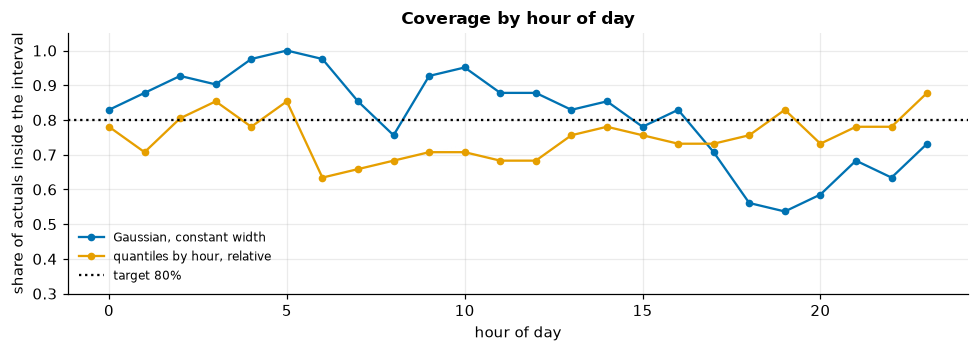

range of hourly coverage, Gaussian: {'min': 0.54, 'max': 1.0}
range of hourly coverage, by hour:  {'min': 0.63, 'max': 0.88}


In [9]:
inside = lambda key: (intervals["actual"] >= intervals[f"{key}_lo"]) & (intervals["actual"] <= intervals[f"{key}_hi"])
by_hour_cov = pd.DataFrame({"Gaussian, constant width": inside("gaussian"), "quantiles by hour, relative": inside("by_hour")}).groupby(intervals["hour"]).mean()

fig, ax = plt.subplots(figsize=(9, 3.3))
by_hour_cov.plot(ax=ax, marker="o", ms=4)
ax.axhline(0.8, color="k", ls=":", label="target 80%")
ax.set(xlabel="hour of day", ylabel="share of actuals inside the interval", ylim=(0.3, 1.05), title="Coverage by hour of day"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("range of hourly coverage, Gaussian:", by_hour_cov["Gaussian, constant width"].agg(["min", "max"]).round(2).to_dict())
print("range of hourly coverage, by hour: ", by_hour_cov["quantiles by hour, relative"].agg(["min", "max"]).round(2).to_dict())

The constant-width Gaussian interval is a textbook case of **good on average, wrong where it matters**. At night its coverage is close to 100% (the interval is much wider than needed), and in the evening peak it falls to about 55% to 65% (too narrow, just when the dispatcher most needs it). The by-hour relative intervals are far more even across the day (about 63% to 88% instead of 54% to 100%), even though each hour's quantiles are estimated from only a few weeks of residuals, which is why they under-cover a little overall.

The residuals method has two virtues and one flaw. It works for **any** forecaster, because it only needs past errors. It is cheap. The flaw is the usual one: it assumes the future errors look like recent errors, so it fails after a regime change or on a holiday, which no interval learned from ordinary days will anticipate.

A different route is a model that predicts the quantiles directly. Gradient boosting supports this with `loss="quantile"`:

In [10]:
X = fc.make_features(y, min_lag=24, lags=(24, 48, 168, 336, 504), windows=(24, 168))
X["same_hour_4w"] = pd.concat([y.shift(168 * k) for k in (1, 2, 3, 4)], axis=1).mean(axis=1)

def quantile_interval(origin, quantiles=(0.1, 0.9)):
    hist = y.loc[: origin - pd.Timedelta(1, "ns")]
    target = pd.date_range(origin, periods=H, freq="h")
    target = target[target <= y.index[-1]]
    rows = X.loc[X.index.isin(hist.index)].dropna()
    out = {}
    for q in quantiles:
        m = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=150, learning_rate=0.05, max_depth=3, random_state=0)
        out[q] = m.fit(rows, hist.loc[rows.index]).predict(X.loc[target])
    return pd.DataFrame({"time": target, "actual": y.loc[target].to_numpy(), "lo": out[quantiles[0]], "hi": out[quantiles[1]]})

gbm_q = pd.concat([quantile_interval(o) for o in sorted(intervals["origin"].unique())], ignore_index=True)
gbm_q["hour"] = gbm_q["time"].dt.hour
covered = (gbm_q["actual"] >= gbm_q["lo"]) & (gbm_q["actual"] <= gbm_q["hi"])
print(f"quantile boosting: coverage {covered.mean():.1%}, average width {(gbm_q['hi'] - gbm_q['lo']).mean():,.0f}, "
      f"interval score {interval_score(gbm_q.assign(), 'lo', 'hi'):,.0f}")
print("hourly coverage range:", covered.groupby(gbm_q["hour"]).mean().agg(["min", "max"]).round(2).to_dict())

quantile boosting: coverage 74.5%, average width 927, interval score 1,519
hourly coverage range: {'min': 0.63, 'max': 0.85}


Quantile boosting covers about 74%, no better than the simple residual method, and is wider, with a worse interval score than the by-hour intervals. With 11 weeks of data there is little to learn tail behaviour from. The model-free residual method is a good default; a quantile model earns its place when there is a lot of data or when the spread depends on drivers the point forecast does not use.

<div class="admonition warning">
<p class="admonition-title">An interval is a claim you can check</p>
<p>"80%" must mean 80% <em>in a test</em>. Always report <b>coverage on held-out origins</b>, broken down by something that matters (hour, weekday, level of demand), next to the width. A narrow interval that covers 50% is not "sharp", it is wrong.</p>
</div>

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| MAPE is `nan`/`inf` or huge | actual values at or near zero | MAE, RMSE or MASE; check the data's range before choosing |
| A silly forecast wins on sMAPE | zeros score as perfect; sMAPE rewards low forecasts | never rely on one metric; include a trivial forecast as a sanity check |
| RMSE jumps when one day is added | squared errors weight outliers | report MAE alongside; look at per-day errors |
| Forecast looks accurate but leans low | MAE ignores the sign | report bias |
| Intervals cover 80% overall but 55% at the busy hours | constant width, varying uncertainty | build intervals by hour, or relative to the forecast; check coverage by group |
| Interval built from errors that include the future | residuals computed after the origin | use only errors already observed at the origin |
| Interval fails on a holiday | residual quantiles come from ordinary days | add holiday information, widen manually, or flag as out of scope |

## Check yourself

<details class="question">
<summary>1. A forecaster has MAPE 5% on city-wide hourly demand. Can you conclude it will do equally well for a single quiet zone?</summary>

No. MAPE depends on the size of the denominator: for a series with demand in the thousands, 5% is a meaningful statement, while for counts near zero the same forecaster's percentage error is undefined or huge. The metric itself does not transfer between scales. Use a scale-free measure that survives zeros, such as MASE, to compare across series of different sizes.

</details>

<details class="question">
<summary>2. The 80% interval covers 82% of the test values. Is it well calibrated?</summary>

Not necessarily: that is the *marginal* coverage. Check it in subgroups: by hour of day, weekday, and demand level. A constant-width interval can cover 100% at night and 55% at the evening peak and still average out near 80%. Calibration that matters is **conditional** on the situation in which the interval will be used.

</details>

<details class="question">
<summary>3. Why must the residuals used for an interval at origin <i>o</i> come only from targets earlier than <i>o</i>?</summary>

At the origin the future errors do not exist yet. Using residuals from after the origin would let the interval 'know' how wrong the forecaster is about to be and would produce coverage numbers that cannot be reproduced in production. It is the same rule as for features: if it is not available at the moment of the forecast, it must not be used.

</details>

## Exercises

<details class="question">
<summary>Build 90% intervals (the 5th and 95th percentiles) with the by-hour relative method. What coverage do you get, and what happens to the width?</summary>

Repeat the interval cell with quantiles 0.05 and 0.95 (and <code>z = 1.645</code> for the Gaussian version), then compute the coverage and the average width.

```python
relative = (known["actual"] / known["forecast"] - 1).groupby(known["hour"]).quantile([0.05, 0.95]).unstack()
```

Coverage rises to about 85%, again a little short of the nominal 90%, and the average width grows by about 37% (from roughly 810 to roughly 1,110 pickups). Wider intervals buy coverage at a steep price; the nominal level is a decision about the cost of being caught out.

</details>

<details class="question">
<summary>Under-forecasting costs three times as much as over-forecasting (a stranded passenger is worse than an idle cab). Which quantile of the error distribution minimises expected cost, and how much better is it than the plain point forecast?</summary>

The cost of an error is $3e$ if you under-forecast by $e$ and $e$ if you over-forecast: the **pinball loss** with $\tau = 0.75$ (under = 3, over = 1 gives $\tau = 3/(3+1)$). It is minimised by the **75th percentile** of the demand distribution, not by the mean.

```python
def cost(df, forecast):
    under = (df["actual"] - forecast).clip(lower=0); over = (forecast - df["actual"]).clip(lower=0)
    return (3 * under + over).mean()

relative75 = (known["actual"] / known["forecast"] - 1).groupby(known["hour"]).quantile(0.75)   # per origin, as above
```

On this data, shifting each forecast up to its 75th percentile cuts the average cost by about 29% (from about 646 to about 458 cost units per hour) compared with using the four-week average as is. The point: the right number to report depends on the cost of the errors, and a point forecast is the answer to only one particular cost structure.

</details>

<details class="question">
<summary>Compute the mean error (bias) of the four-week average for each hour of the day. In which hours does it under-forecast most?</summary>

```python
print((ev["forecast"] - ev["actual"]).groupby(ev["time"].dt.hour).mean().round(0))
```

The forecaster under-forecasts at almost every hour: the bias is about −110 to −200 pickups in the evening (5 to 11pm), about −130 around 11am and midnight, and only 7am is (slightly) positive. That fits the overall bias of about −78 and a rising level that a four-week average lags. Bias by hour is a cheap check that points at a systematic fix (correct for the trend), whereas MAE alone would not show it.

</details>

## Recap

- Metrics are questions. **MAE** for typical miss, **RMSE** when big misses are costly, **bias** for direction, **MASE** for comparisons across series.
- **MAPE** and **sMAPE** break near zero; sMAPE can reward a nonsense forecast. Always check metrics on the shape of your data, and include a trivial forecast as a sanity check.
- A prediction interval is a **claim about coverage**: test it on held-out origins and *by group*; marginal coverage hides local failure.
- Intervals from **past errors** work with any forecaster. Build them from errors already known at the origin, by hour, relative to the forecast.
- The number you should report depends on the cost of errors: asymmetric costs call for a quantile, not a mean.

**Next:** *Holidays, outside drivers and regime change*.